# Weighting returns by average uniqueness

An active event receives an equal share of a price interval, and its average share over its life is its average uniqueness:

$$
u_{ti}=\frac{I_{ti}}{c_t},\qquad
\overline u_i=\frac{\sum_t u_{ti}}{\sum_t I_{ti}}.
$$

Here, $u_{ti}$ is event $i$'s uniqueness at time $t$; $I_{ti}$ is its activity indicator; $c_t$ is concurrency. $\overline u_i\in[0,1]$ is average uniqueness; the denominator $\sum_t I_{ti}$ is event $i$'s length.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.labeling import cusum_filter_events_dynamic_threshold, daily_volatility_with_log_returns, vertical_barrier
from RiskLabAI.data.weights import calculate_average_uniqueness, calculate_time_decay, expand_label_for_meta_labeling, sample_weight_absolute_return_meta_labeling

FIGURES = ROOT / "outputs" / "figures" / "07_overlapping_information_weights"
TABLES = ROOT / "outputs" / "tables" / "07_overlapping_information_weights"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

raw = raw.sort_values("time").dropna(subset=["time", "close"]).drop_duplicates("time").reset_index(drop=True)
minute_close = pd.Series(raw["close"].to_numpy(dtype=float), index=pd.DatetimeIndex(raw["time"]), name="One-minute close")
close = minute_close.resample("15min").last().dropna().rename("Fifteen-minute close")
log_price = np.log(close)
volatility = daily_volatility_with_log_returns(close, span=100)
event_times = cusum_filter_events_dynamic_threshold(log_price, volatility.dropna())
event_ends = vertical_barrier(close, event_times, number_days=1)
event_times = event_times.intersection(event_ends.index).intersection(volatility.dropna().index)
event_ends = event_ends.loc[event_times]

def build_indicator_matrix(index, ends):
    matrix = pd.DataFrame(0, index=index, columns=ends.index, dtype=np.int8)
    for start, end in ends.items():
        matrix.loc[start:end, start] = 1
    return matrix

indicator_matrix = build_indicator_matrix(close.index, event_ends)
event_duration = indicator_matrix.sum(axis=0).astype(int)
matrix_concurrency = indicator_matrix.sum(axis=1).astype(int)
active_concurrency = matrix_concurrency[matrix_concurrency > 0]
library_concurrency = expand_label_for_meta_labeling(close.index, event_ends, event_times).astype(int)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Exact Allocation of Shared Information

In [2]:
controlled_matrix = pd.DataFrame([[1, 0, 1], [1, 1, 1], [1, 1, 0], [0, 1, 0]], columns=["Event A", "Event B", "Event C"])
controlled_uniqueness = calculate_average_uniqueness(controlled_matrix)
controlled_table = pd.DataFrame({"Event": controlled_uniqueness.index, "Average uniqueness": controlled_uniqueness.to_numpy(), "Exact value": ["4/9", "11/18", "5/12"]})
average_uniqueness = calculate_average_uniqueness(indicator_matrix)
active_records = int((matrix_concurrency > 0).sum())
allocated_records = float((average_uniqueness * event_duration).sum())
uniqueness_summary = pd.DataFrame({
    "Summary": ["Smallest", "10th percentile", "Middle value", "Mean", "90th percentile", "Largest", "Allocated active records"],
    "Value": [average_uniqueness.min(), average_uniqueness.quantile(0.10), average_uniqueness.median(), average_uniqueness.mean(), average_uniqueness.quantile(0.90), average_uniqueness.max(), allocated_records],
})
save_table(controlled_table, "controlled_uniqueness", "Exact average uniqueness for a three-event example.", "tab:chapter6-controlled-uniqueness", fit=False)
save_table(uniqueness_summary, "uniqueness_summary", "Average uniqueness in the public January event sample.", "tab:chapter6-uniqueness-summary", fit=False)
display(controlled_table)
display(uniqueness_summary.round(6))

,Event,Average uniqueness,Exact value
0,Event A,0.444444,4/9
1,Event B,0.611111,11/18
2,Event C,0.416667,5/12


,Summary,Value
0,Smallest,0.104516
1,10th percentile,0.115052
2,Middle value,0.184855
3,Mean,0.216650
4,90th percentile,0.376151
5,Largest,0.814433
6,Allocated active records,2795


Every active price interval contributes one full unit of information, divided among its active events without loss or duplication:

$$
\sum_{i=1}^{n}u_{ti}=\mathbf 1\{c_t>0\},\qquad
\sum_{i=1}^{n}L_i\overline u_i=\#\{t:c_t>0\}.
$$

Here, $n$ is the number of events; $u_{ti}$ is event-level uniqueness; $c_t$ is concurrency. $L_i=\sum_t I_{ti}$ is event length; $\overline u_i$ is average uniqueness; $\#\{t:c_t>0\}$ counts active intervals.

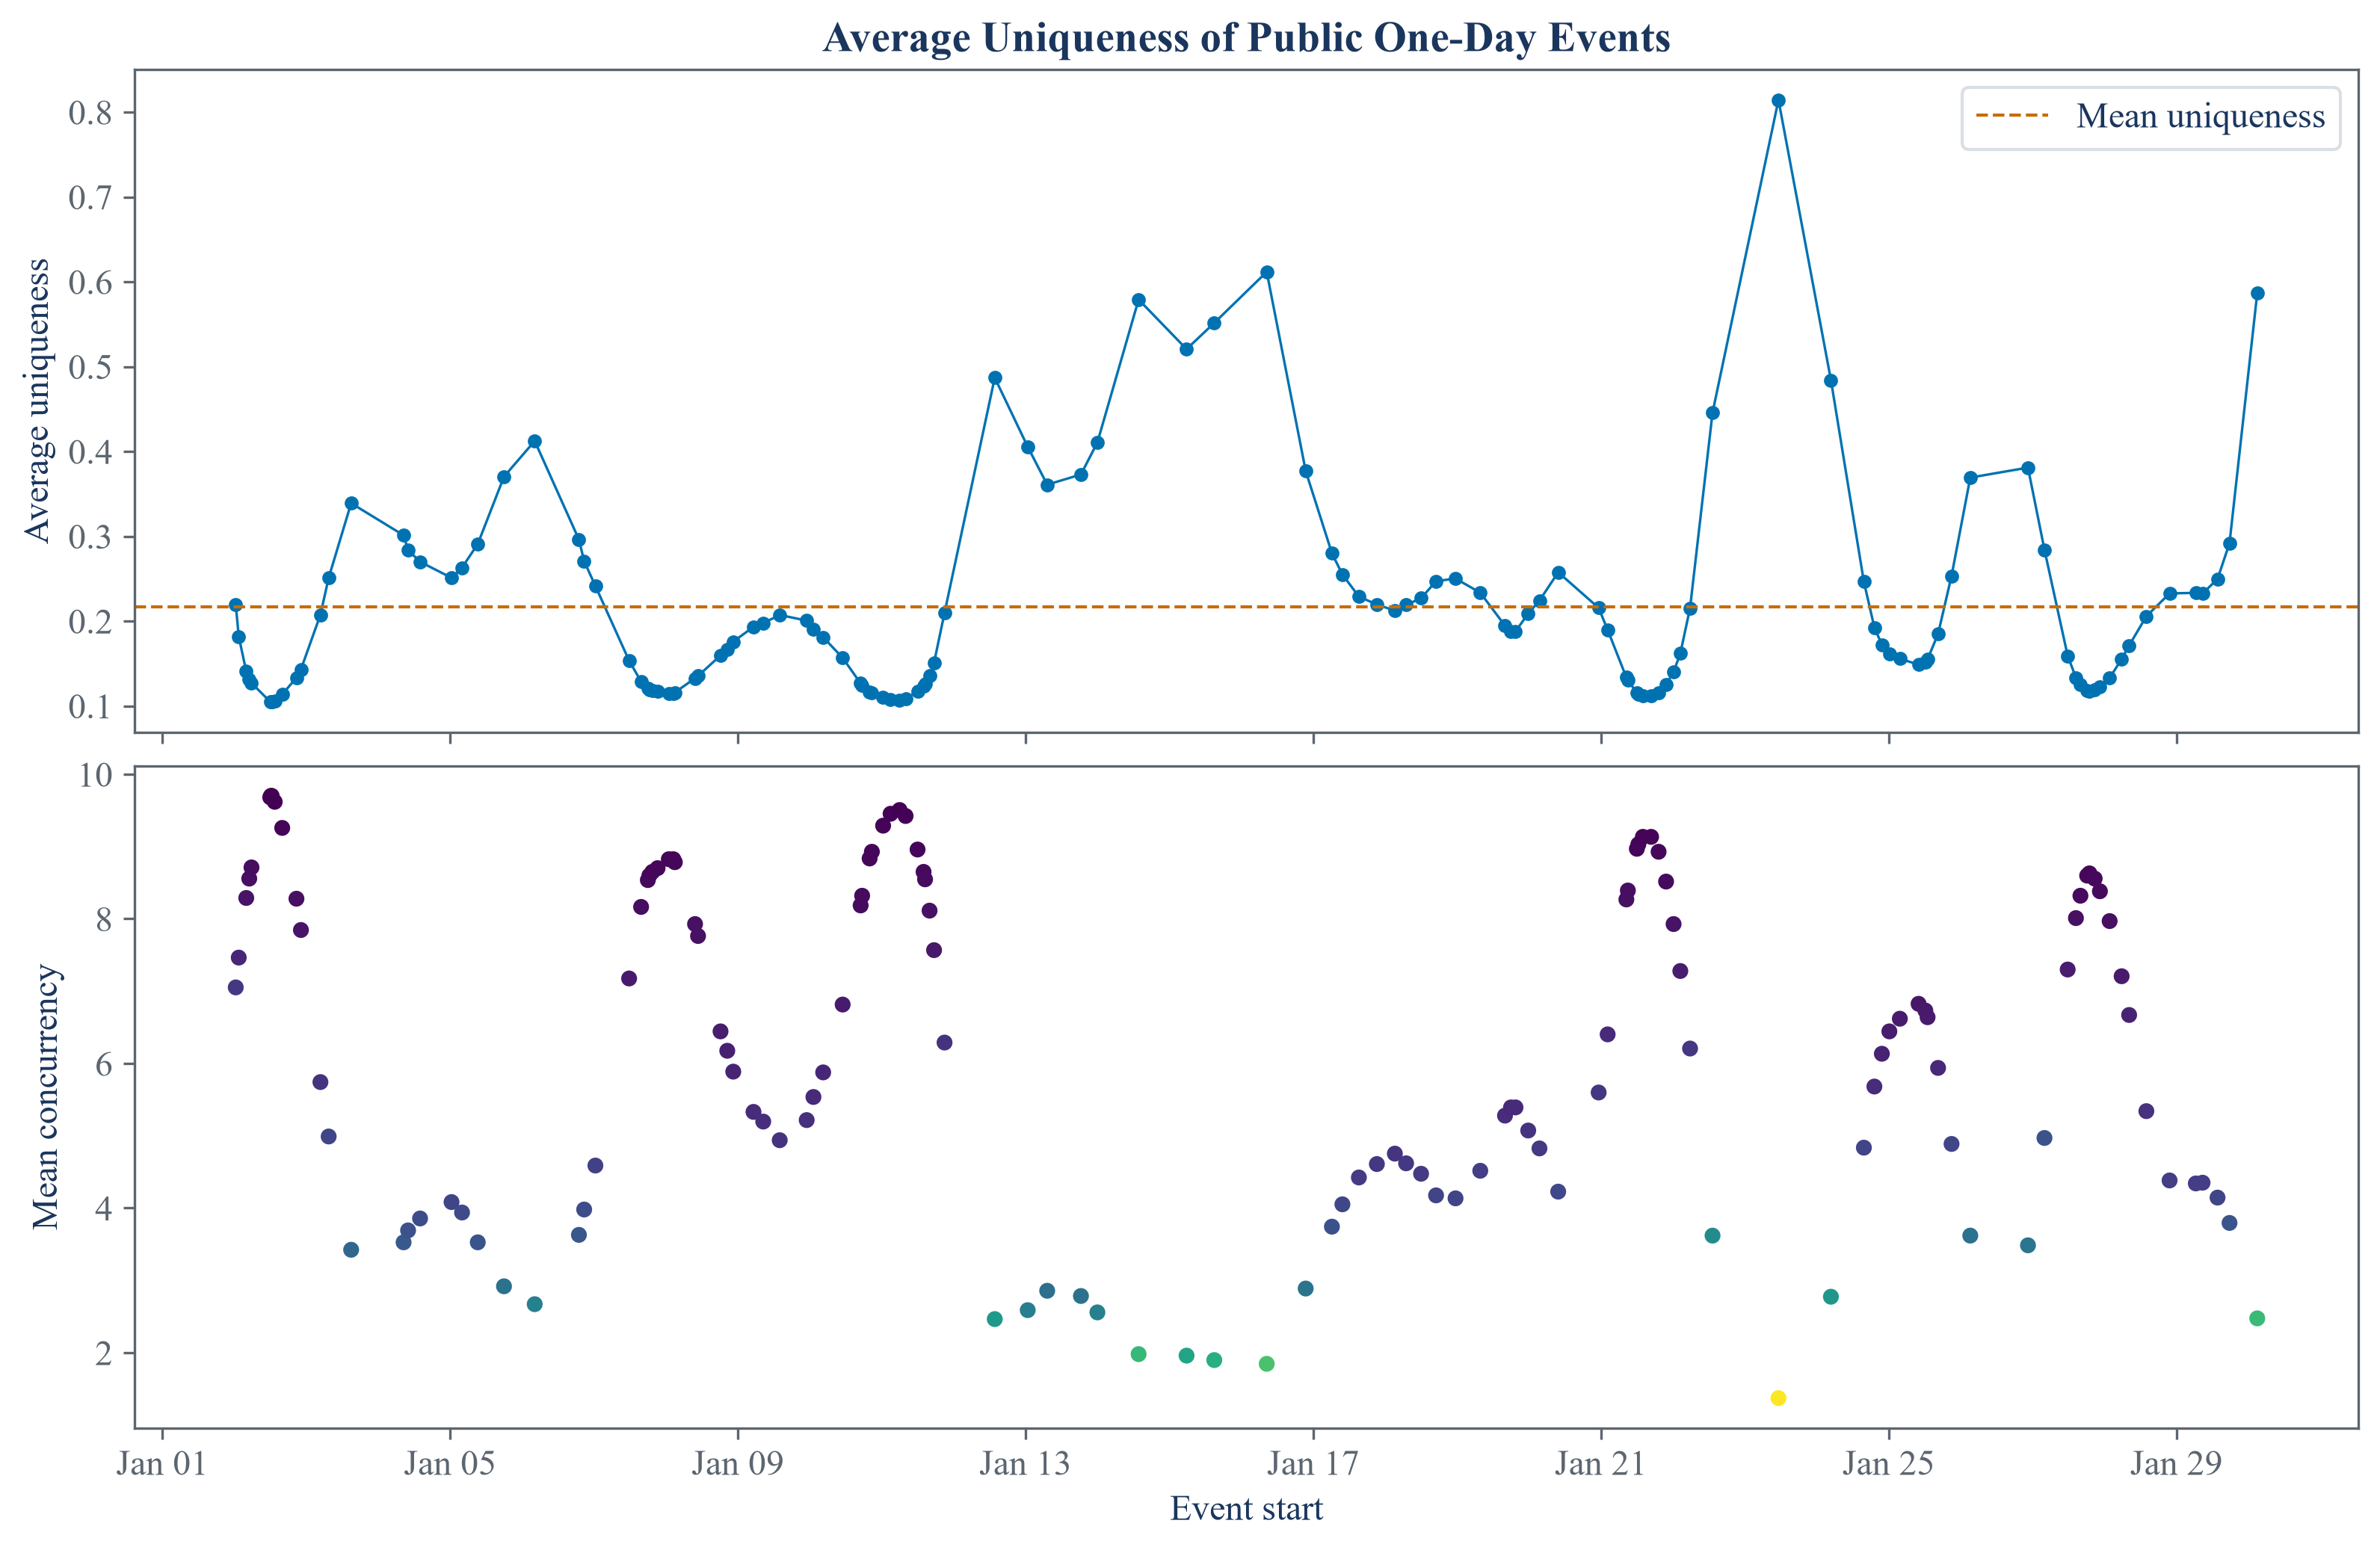

In [3]:
interval_uniqueness = indicator_matrix.div(matrix_concurrency.replace(0, np.nan), axis=0).fillna(0.0)
figure, axes = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True, constrained_layout=True)
axes[0].plot(event_times, average_uniqueness, color=palette["cyan"], marker="o", markersize=3.5, linewidth=0.8)
axes[0].axhline(average_uniqueness.mean(), color=palette["amber"], linestyle="--", linewidth=1.0, label="Mean uniqueness")
axes[0].set_ylabel("Average uniqueness")
axes[0].set_title("Average Uniqueness of Public One-Day Events")
axes[0].legend()
mean_concurrency_by_event = pd.Series({start: matrix_concurrency.loc[start:end].mean() for start, end in event_ends.items()})
axes[1].scatter(event_times, mean_concurrency_by_event, c=average_uniqueness, cmap="viridis", s=26, edgecolors="none")
axes[1].set_ylabel("Mean concurrency")
axes[1].set_xlabel("Event start")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
figure.savefig(FIGURES / "uniqueness_profile.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "uniqueness_profile.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "uniqueness_profile.png")))
plt.close(figure)

## Return Attribution

An event receives its share of absolute price movement, then all event weights are scaled to have average one:

$$
\widetilde w_i=\sum_t I_{ti}\frac{|r_t|}{c_t},\qquad
w_i=n\frac{\widetilde w_i}{\sum_{j=1}^{n}\widetilde w_j},\qquad
\sum_{i=1}^{n}w_i=n.
$$

Here, $r_t=\log P_t-\log P_{t-1}$ is the log return; $I_{ti}$ is the event indicator; $c_t$ is concurrency. $\widetilde w_i$ is unscaled attributed movement; $w_i$ is the normalized weight; $n$ is the number of events.

,Event start,Event end,Average uniqueness,Absolute movement,Normalized attribution weight
0,2021-01-12 13:45:00,2021-01-13 13:45:00,0.486942,0.736802,3.145415
1,2021-01-15 15:00:00,2021-01-16 15:00:00,0.551546,0.589612,2.709849
2,2021-01-15 05:45:00,2021-01-16 05:45:00,0.520619,0.547672,2.429369
3,2021-01-16 08:30:00,2021-01-17 08:30:00,0.611684,0.456017,2.244910
4,2021-01-06 04:15:00,2021-01-07 04:15:00,0.412371,0.581643,2.078125
5,2021-01-03 15:00:00,2021-01-04 15:00:00,0.339003,0.698836,2.060350
6,2021-01-13 00:45:00,2021-01-14 00:45:00,0.405498,0.571932,2.022701
7,2021-01-04 08:30:00,2021-01-05 08:30:00,0.301203,0.776846,2.014281


,Summary,Value
0,Smallest weight,0.425768
1,Middle weight,0.788215
2,Mean weight,1
3,Largest weight,3.145415
4,Uniqueness-weight correlation,0.741252
5,Eight largest weights' share,0.140639


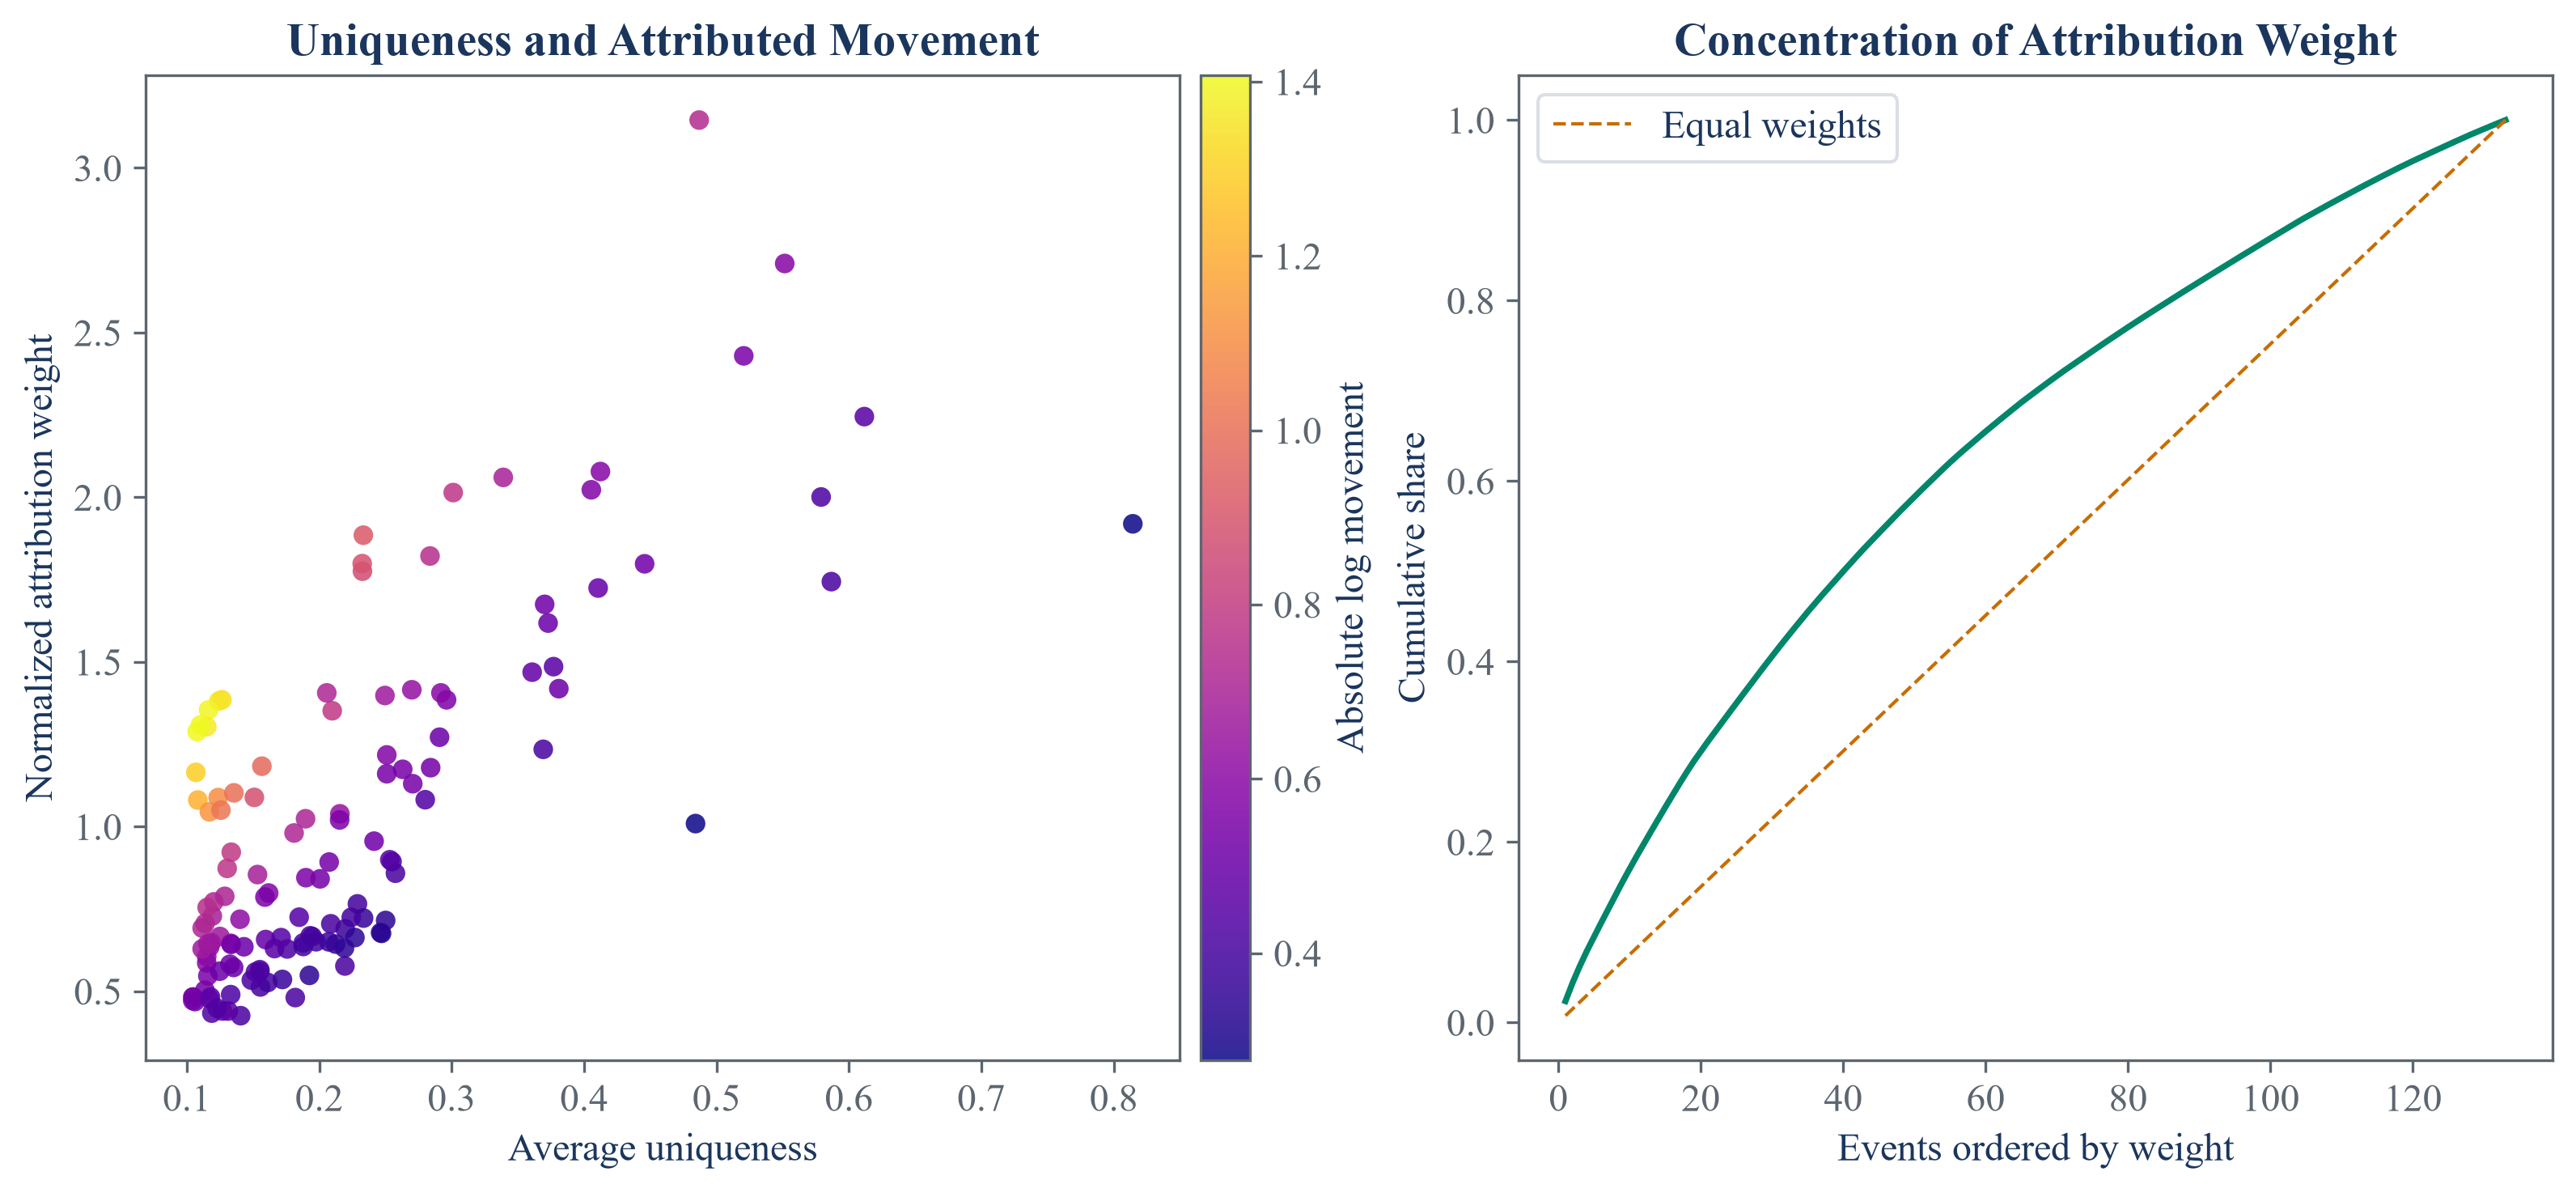

In [4]:
attribution_weights = sample_weight_absolute_return_meta_labeling(event_ends, close, event_times)
absolute_log_return = np.log(close).diff().abs()
aligned_concurrency = library_concurrency.reindex(close.index, fill_value=0)
manual_raw = pd.Series(index=event_times, dtype=float)
for start, end in event_ends.items():
    event_concurrency = aligned_concurrency.loc[start:end]
    active = event_concurrency > 0
    manual_raw.loc[start] = (absolute_log_return.loc[start:end][active] / event_concurrency[active]).sum()
manual_weights = manual_raw * len(manual_raw) / manual_raw.sum()
attributed_movement = pd.Series({start: absolute_log_return.loc[start:end].sum() for start, end in event_ends.items()})
event_results = pd.DataFrame({"Event start": event_times, "Event end": event_ends.to_numpy(), "Average uniqueness": average_uniqueness.to_numpy(), "Absolute movement": attributed_movement.to_numpy(), "Normalized attribution weight": attribution_weights.to_numpy()})
top_weights = event_results.nlargest(8, "Normalized attribution weight").reset_index(drop=True)
weight_summary = pd.DataFrame({
    "Summary": ["Smallest weight", "Middle weight", "Mean weight", "Largest weight", "Uniqueness-weight correlation", "Eight largest weights' share"],
    "Value": [attribution_weights.min(), attribution_weights.median(), attribution_weights.mean(), attribution_weights.max(), average_uniqueness.corr(attribution_weights), top_weights["Normalized attribution weight"].sum() / attribution_weights.sum()],
})
save_table(top_weights, "attribution_weight_summary", "Eight events with the largest normalized attribution weights.", "tab:chapter6-attribution-weights", fit=True)
display(top_weights.round({column: 6 for column in top_weights.select_dtypes(include="number").columns}))
display(weight_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), constrained_layout=True)
scatter = axes[0].scatter(average_uniqueness, attribution_weights, c=attributed_movement, cmap="plasma", s=34, alpha=0.86, edgecolors="none")
axes[0].set_xlabel("Average uniqueness")
axes[0].set_ylabel("Normalized attribution weight")
axes[0].set_title("Uniqueness and Attributed Movement")
colorbar = figure.colorbar(scatter, ax=axes[0], pad=0.02)
colorbar.set_label("Absolute log movement")
ordered_weights = np.sort(attribution_weights.to_numpy())[::-1]
axes[1].plot(np.arange(1, len(ordered_weights) + 1), np.cumsum(ordered_weights) / ordered_weights.sum(), color=palette["green"], linewidth=1.8)
axes[1].plot([1, len(ordered_weights)], [1 / len(ordered_weights), 1], color=palette["amber"], linestyle="--", linewidth=1.0, label="Equal weights")
axes[1].set_xlabel("Events ordered by weight")
axes[1].set_ylabel("Cumulative share")
axes[1].set_title("Concentration of Attribution Weight")
axes[1].legend()
figure.savefig(FIGURES / "attribution_weights.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "attribution_weights.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "attribution_weights.png")))
plt.close(figure)

## Weight Distribution Through Time

,Summary,Normalized attribution weight
0,Smallest,0.425768
1,10th percentile,0.505160
2,25th percentile,0.634258
3,Middle value,0.788215
4,75th percentile,1.288599
5,90th percentile,1.793484
6,Largest,3.145415
7,Mean,1


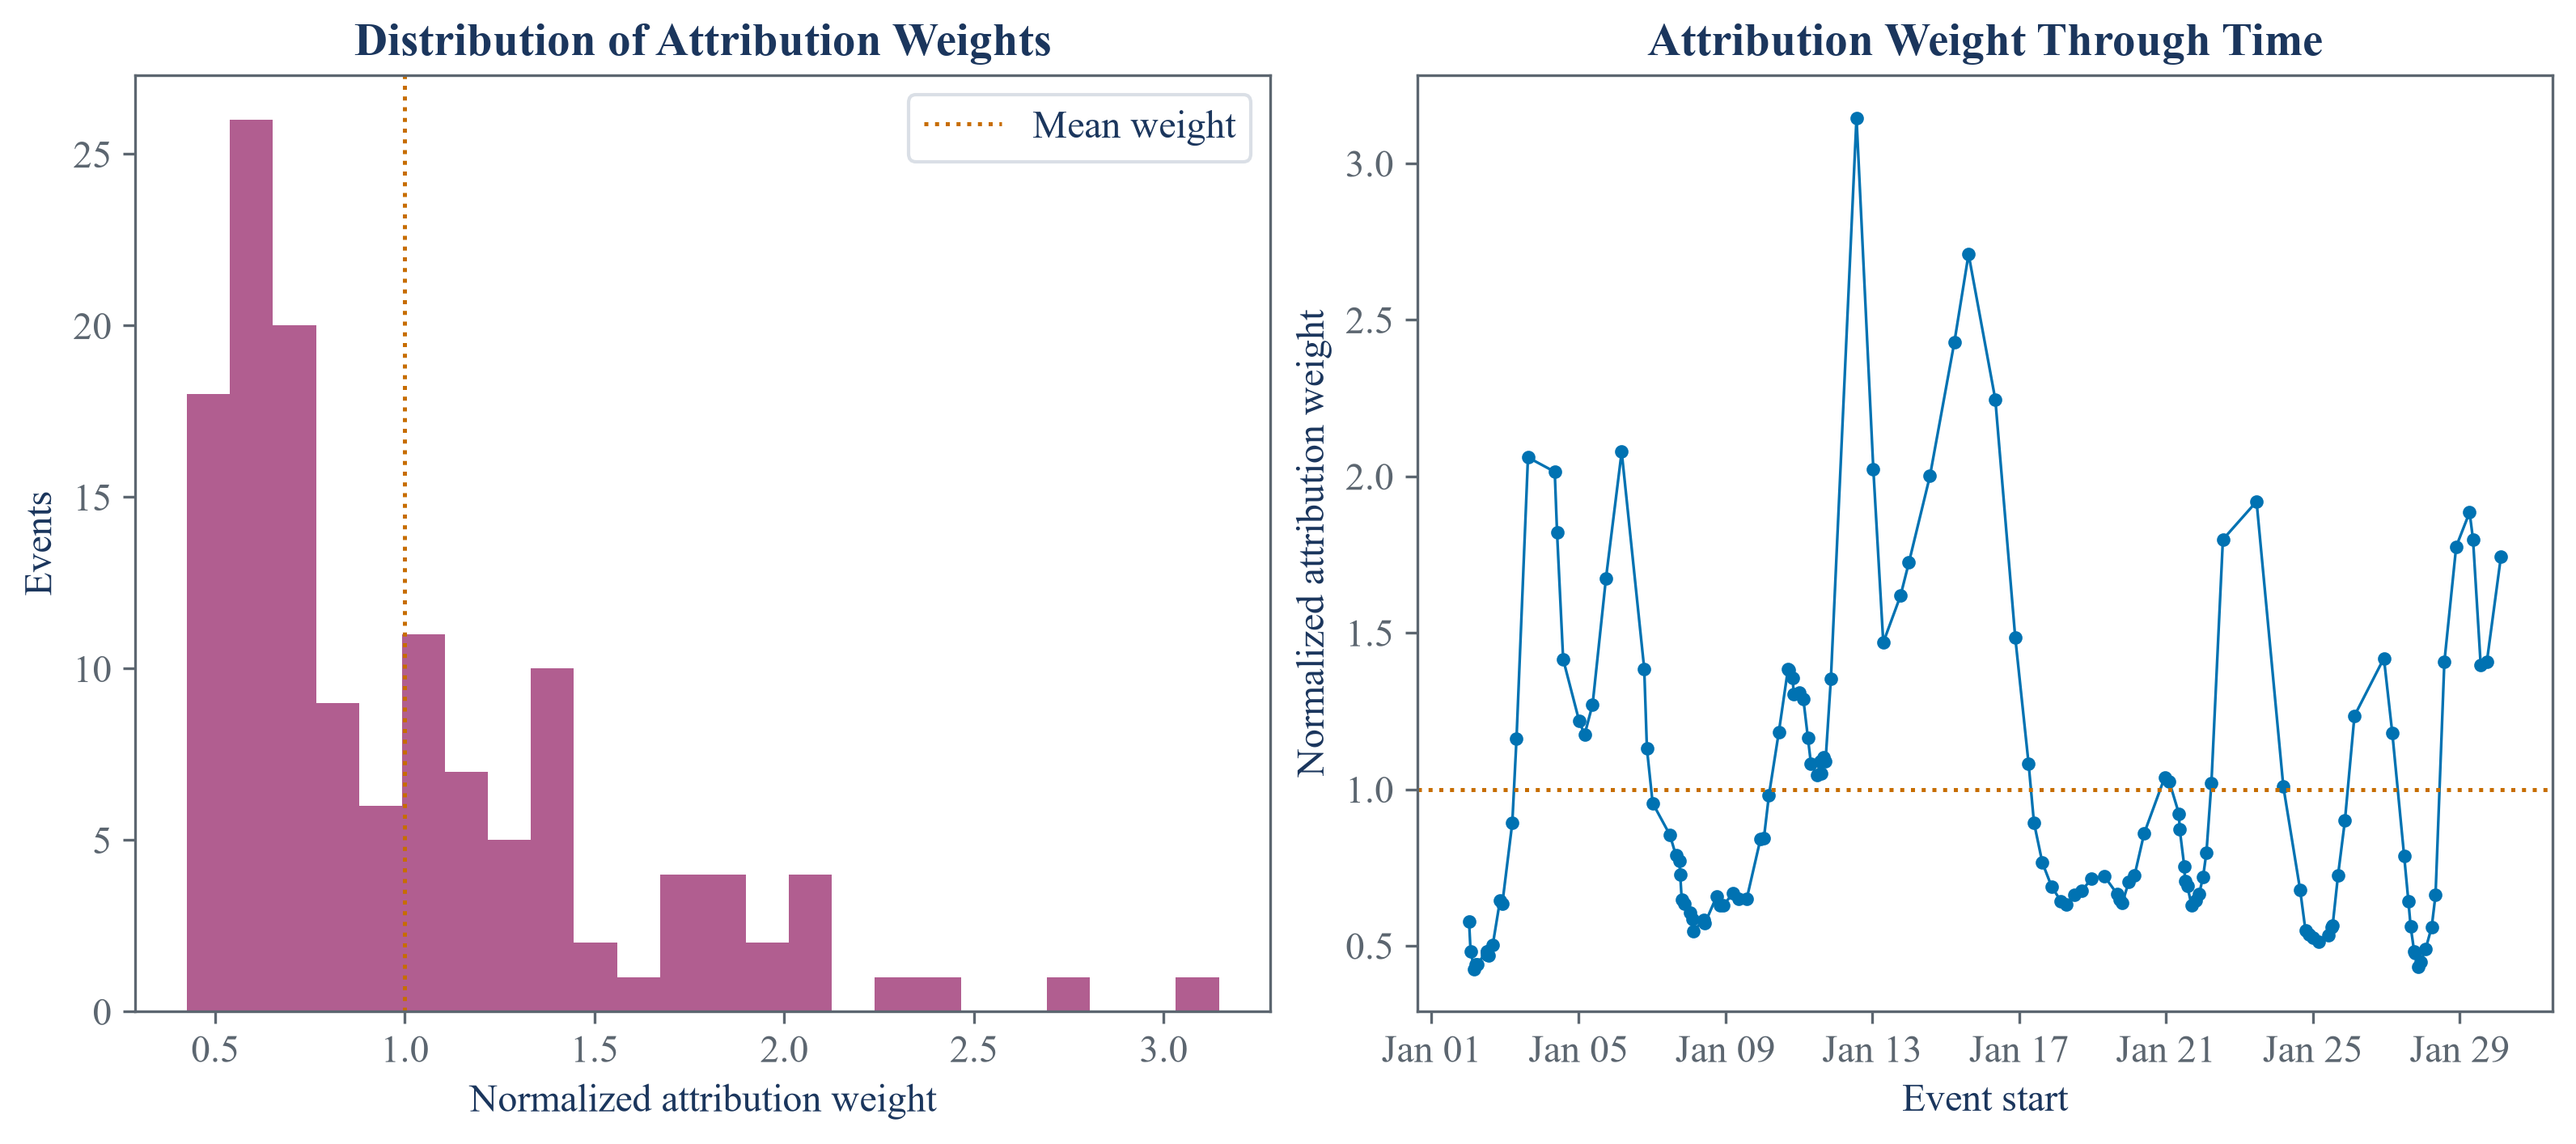

In [5]:
weight_distribution_summary = pd.DataFrame({
    "Summary": ["Smallest", "10th percentile", "25th percentile", "Middle value", "75th percentile", "90th percentile", "Largest", "Mean"],
    "Normalized attribution weight": [attribution_weights.min(), attribution_weights.quantile(0.10), attribution_weights.quantile(0.25), attribution_weights.median(), attribution_weights.quantile(0.75), attribution_weights.quantile(0.90), attribution_weights.max(), attribution_weights.mean()],
})
save_table(weight_distribution_summary, "attribution_weight_distribution", "Distribution of normalized absolute-return attribution weights.", "tab:chapter6-attribution-weight-distribution", fit=False)
display(weight_distribution_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
axes[0].hist(attribution_weights, bins=24, color=palette["violet"], alpha=0.82)
axes[0].axvline(1.0, color=palette["amber"], linewidth=1.2, linestyle=":", label="Mean weight")
axes[0].set_title("Distribution of Attribution Weights")
axes[0].set_xlabel("Normalized attribution weight")
axes[0].set_ylabel("Events")
axes[0].legend()
axes[1].plot(event_times, attribution_weights, color=palette["cyan"], marker="o", markersize=3.0, linewidth=0.8)
axes[1].axhline(1.0, color=palette["amber"], linewidth=1.2, linestyle=":")
axes[1].set_title("Attribution Weight Through Time")
axes[1].set_xlabel("Event start")
axes[1].set_ylabel("Normalized attribution weight")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
figure.savefig(FIGURES / "attribution_weight_distribution.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "attribution_weight_distribution.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "attribution_weight_distribution.png")))
plt.close(figure)

## Tests

In [6]:
expected_controlled = np.array([4 / 9, 11 / 18, 5 / 12])
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(event_times) == 133
assert np.allclose(controlled_uniqueness.to_numpy(), expected_controlled)
assert np.all((average_uniqueness >= 0.0) & (average_uniqueness <= 1.0))
assert np.allclose(interval_uniqueness.sum(axis=1).loc[matrix_concurrency > 0], 1.0)
assert np.allclose(interval_uniqueness.sum(axis=1).loc[matrix_concurrency == 0], 0.0)
assert np.isclose(allocated_records, active_records)
assert active_records == 2795
assert np.allclose(attribution_weights.to_numpy(), manual_weights.to_numpy())
assert np.isclose(attribution_weights.sum(), len(event_times))
assert np.isclose(attribution_weights.mean(), 1.0)
assert (attribution_weights > 0.0).all()
assert average_uniqueness.corr(attribution_weights) > 0.70
assert top_weights["Normalized attribution weight"].is_monotonic_decreasing
assert event_results["Event end"].gt(event_results["Event start"]).all()
assert len(weight_distribution_summary) == 8
assert np.isclose(weight_distribution_summary.loc[weight_distribution_summary["Summary"] == "Mean", "Normalized attribution weight"].iloc[0], 1.0)
assert (FIGURES / "attribution_weight_distribution.pdf").is_file()
assert (TABLES / "attribution_weight_distribution.tex").is_file()